# Decision Tree Regression

**The big picture:** the same salary data again: 10 job levels, from Business Analyst (level 1, $45,000) to CEO (level 10, $1,000,000). The goal is to predict the salary for a level like 6.5.

A decision tree works like a game of **20 Questions**. It asks yes/no questions such as "Is the level 6.5 or less?", splitting the data into smaller and smaller groups. Each final group (a **leaf**) predicts the **average salary** of the training rows in it. There is no formula or curve, just a set of rules.

### Before you start
- **Read first:** **polynomial_regression** and **support_vector_regression**: they use the same salary data, so you can compare a smooth curve with the tree's staircase.
- **New words in this notebook:** *decision tree*, *split (cut-off)*, *leaf*, *random_state*, *max_depth*, *staircase prediction*. Look them up in the [glossary](../../../GLOSSARY.md) if you get stuck.

## Importing the libraries

- **pandas** reads and handles tables, like Excel in Python.
- **numpy** does fast maths on lists of numbers.
- **matplotlib** draws charts. Here it is used to plot the salaries and the model's predictions.

In [0]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Importing the dataset

- Reads the CSV file into a table. It has 10 rows, one per job: *Position* (e.g. "Manager"), *Level* (1 to 10) and *Salary*.
- **X** = `iloc[:, 1:-1]`, which means "from column 1 up to, but not including, the last one". That is just the **Level** column. This is the **input**.
- **y** = the last column, *Salary*. This is what we want to **predict**.

**Why skip the Position column?** The job title and the level say the same thing ("Manager" is level 4), so the number is all the model needs. Writing `1:-1` instead of just `1` also keeps X as a **table with one column** rather than a flat list, which is the shape scikit-learn expects.

There is **no train/test split** in this notebook. With only 10 rows there is too little data to hold any back, so the model learns from all of it.

There is also **no feature scaling**. A tree only asks "is this value above or below a cut-off?", so the size of the numbers doesn't matter.

In [0]:
dataset = pd.read_csv('Position_Salaries.csv')
X = dataset.iloc[:, 1:-1].values
y = dataset.iloc[:, -1].values

## Training the Decision Tree Regression model on the whole dataset

- `DecisionTreeRegressor` creates the tree.
- `random_state = 0` makes the result the same on every run. When two possible questions are equally good, the tree picks between them at random, and this fixes that choice.
- `.fit(X, y)` builds the tree. At each step it picks the cut-off that best separates high salaries from low ones (the one with the smallest squared error, `criterion='mse'` in the printout).
- The defaults let the tree keep splitting until every leaf holds **just one job** (`min_samples_leaf=1`). With 10 rows, that means 10 leaves, one per level.

In [3]:
from sklearn.tree import DecisionTreeRegressor
regressor = DecisionTreeRegressor(random_state = 0)
regressor.fit(X, y)

DecisionTreeRegressor(ccp_alpha=0.0, criterion='mse', max_depth=None,
                      max_features=None, max_leaf_nodes=None,
                      min_impurity_decrease=0.0, min_impurity_split=None,
                      min_samples_leaf=1, min_samples_split=2,
                      min_weight_fraction_leaf=0.0, presort='deprecated',
                      random_state=0, splitter='best')

## Predicting a new result

- Asks for the salary at **level 6.5**. The double brackets `[[6.5]]` make it a one-row, one-column table.
- The answer is exactly **$150,000**, the Region Manager's (level 6) salary.

**Why exactly that?** The tree doesn't blend neighbours. The cut-off between levels 6 and 7 sits at 6.5, and "6.5 or less" goes to level 6's leaf, so the tree returns that leaf's salary unchanged.

In [4]:
regressor.predict([[6.5]])

array([150000.])

## Visualising the Decision Tree Regression results (higher resolution)

- `X_grid` runs from level 1 up to just under 10 in tiny steps of **0.01** (900 points), reshaped into a one-column table.
- **Red dots** = real salaries. **Blue line** = the tree's prediction at every grid point.

**How to read it:** the blue line is a **staircase**: flat steps with sudden jumps. Every level within a step gets the same salary, and the jumps happen halfway between the real levels.

**Why the tiny steps?** If you only plotted the 10 real levels, the line would join them with slopes and hide the staircase. Plotting many close points reveals what the tree really does.

With one input and 10 rows, a tree just copies the nearest salary. Trees become much more useful with many inputs and lots of data.

**In one sentence:** load the 10-level salary scale, let a decision tree split it into one group per level, predict level 6.5 (it returns level 6's $150k), and plot the staircase that the tree's rules produce.

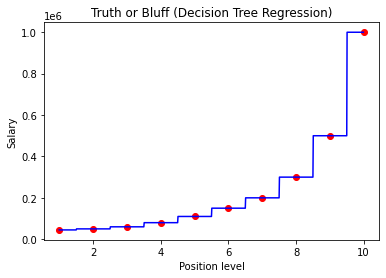

In [5]:
X_grid = np.arange(min(X), max(X), 0.01)
X_grid = X_grid.reshape((len(X_grid), 1))
plt.scatter(X, y, color = 'red')
plt.plot(X_grid, regressor.predict(X_grid), color = 'blue')
plt.title('Truth or Bluff (Decision Tree Regression)')
plt.xlabel('Position level')
plt.ylabel('Salary')
plt.show()

## Common mistakes to avoid
- **Plotting only the 10 real levels.** `plt.plot(X, regressor.predict(X))` joins the 10 predictions with slopes and makes the tree look like a smooth line. Use a fine grid like the notebook's `np.arange(min(X), max(X), 0.01)` to see the real staircase.
- **Letting the tree grow without limits on real data.** With the defaults (`max_depth=None`, `min_samples_leaf=1`) the tree keeps splitting until every leaf holds one row, so it simply memorises the training data. On bigger datasets set `max_depth` or `min_samples_leaf` to stop it overfitting.
- **Expecting the tree to extrapolate.** A tree can only return salaries it has seen (leaf averages). Ask for level 15 and it returns the CEO's $1,000,000, not a higher number. Don't use it to predict beyond the range of your data.
- **Scaling the data "just in case".** Trees only compare values to cut-offs, so scaling changes nothing but adds steps and makes predictions harder to read. You can skip it here, unlike in SVR.

## Try this yourself
Change one thing, rerun the notebook, and see what happens.

1. In the training cell, change `DecisionTreeRegressor(random_state = 0)` to `DecisionTreeRegressor(max_depth = 2, random_state = 0)`, then rerun the training, prediction and chart cells. What to notice: the staircase has only a few wide steps, and the 6.5 prediction is now an average of several jobs instead of exactly $150,000.
2. In the prediction cell, change `[[6.5]]` to `[[6.4]]`, then `[[6.6]]`, then `[[15]]`. What to notice: 6.4 still gives $150,000 but 6.6 jumps to level 7's $200,000, because the cut-off sits at 6.5. Level 15 just returns the CEO's salary; a tree can't go beyond what it has seen.
3. In the chart cell, change the step `0.01` in `np.arange(min(X), max(X), 0.01)` to `1`. What to notice: with only whole levels, the blue line joins the dots with slopes and the staircase disappears, which is why the notebook uses tiny steps.
4. Try `DecisionTreeRegressor(min_samples_leaf = 3, random_state = 0)` and rerun. What to notice: each leaf must hold at least 3 jobs, so the steps get wider and the model stops copying each salary exactly.

## Check your understanding
Try to answer in your head first, then click to reveal.

**1. Why does the tree predict exactly $150,000 for level 6.5?**

<details><summary>Show answer</summary>

Each leaf holds one job here, and the cut-off between levels 6 and 7 is at 6.5. "6.5 or less" falls into level 6's leaf, so the tree returns the Region Manager's $150,000 unchanged. It never blends neighbours.

</details>

**2. Why doesn't this notebook use feature scaling?**

<details><summary>Show answer</summary>

A tree only asks "is this value above or below a cut-off?". Whether levels are 1 to 10 or -1.57 to 1.57, the same rows end up on the same side, so the size of the numbers doesn't matter.

</details>

**3. In the chart, what does the staircase shape of the blue line tell you?**

<details><summary>Show answer</summary>

Every level inside a step gets the same predicted salary, and the jumps happen halfway between real levels. That is what a tree does: it splits the input into ranges and gives each range one fixed answer.

</details>

**4. What would happen if you set `max_depth = 1`?**

<details><summary>Show answer</summary>

The tree could ask only one question, so it would have just two leaves. The chart would show a single jump, and every level would get one of two average salaries.

</details>

---
📚 [Learning path](../../../LEARNING_PATH.md) · [Glossary](../../../GLOSSARY.md)